In [17]:
import os
import idx2numpy
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

file_path = './data/t10k-images.idx3-ubyte'
images = idx2numpy.convert_from_file(file_path)
labels = idx2numpy.convert_from_file('./data/t10k-labels.idx1-ubyte')

In [18]:
print(f"Forma original de las imágenes: {images.shape}")
print(f"Forma de las etiquetas: {labels.shape}")

Forma original de las imágenes: (10000, 28, 28)
Forma de las etiquetas: (10000,)


In [19]:
n_samples = images.shape[0]
X = images.reshape(n_samples, -1)
y = labels

In [20]:
print(f"Forma transformada (matriz X): {X.shape}")

Forma transformada (matriz X): (10000, 784)


In [21]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [22]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [23]:
print(f"Forma de los datos tras PCA: {X_pca.shape}")
print(f"Varianza explicada por los 2 componentes: {pca.explained_variance_ratio_ * 100}%")

Forma de los datos tras PCA: (10000, 2)
Varianza explicada por los 2 componentes: [6.19682546 4.24374595]%


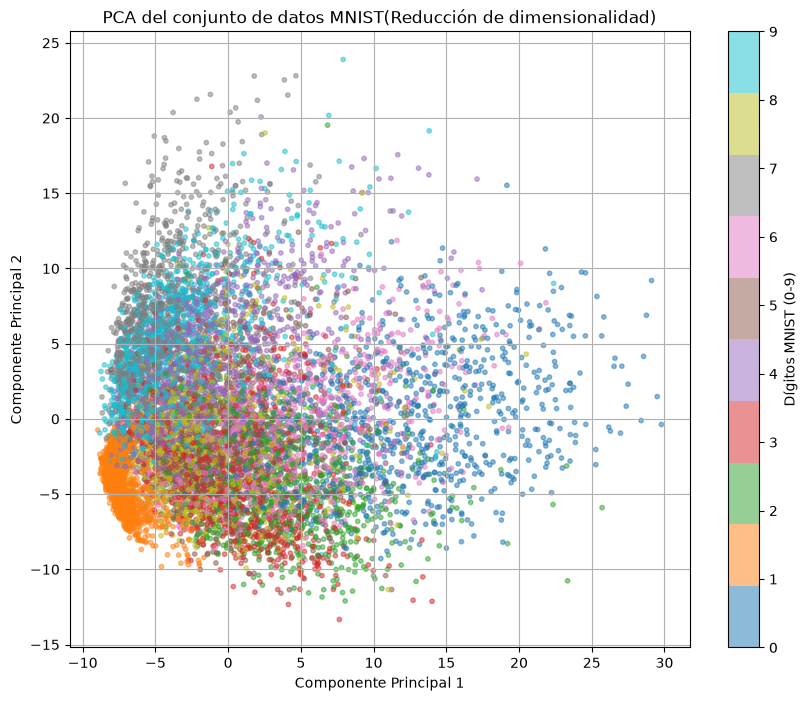

In [24]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='tab10', alpha=0.5, s=10)
plt.colorbar(scatter, label='Dígitos MNIST (0-9)')
plt.title('PCA del conjunto de datos MNIST(Reducción de dimensionalidad)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()